# AutoPilotRL — v4: Double DQN, Dueling, and attention over vehicles

## Where we are
| Driver | Return | Crash rate | Mean speed |
|---|---|---|---|
| v1 rule-based | 22.83 | **2%** | 22.5 m/s |
| v2 Q-learning (hand-made features) | **23.05** | 8% | 23.0 m/s |
| v3 DQN (MLP on 10 raw vehicles) | 20.55 | 18% | 21.9 m/s |

The v3 DQN was worse than the table. The diagnosis:
1. its values were **overestimated** by about 2.5;
2. its input is a flat list of 10 rows, where "the car ahead in my lane" can be any row: a plain MLP must learn this for every row separately;
3. it trained for only about 1,250 episodes, and its model selection used just 20 validation episodes.

## The idea of v4
One change for each problem:

| Problem | Fix |
|---|---|
| Overestimation | **Double DQN** (van Hasselt et al., 2016) |
| Many situations where all actions are worth about the same | **Dueling** heads (Wang et al., 2016) |
| A list of vehicles in arbitrary order | **Attention over vehicles**: the ego car "looks at" the other cars (Leurent & Mercat, *Social Attention for Autonomous Decision-Making in Dense Traffic*, 2019, the authors of highway-env) |
| Too little training, noisy selection | 50,000 steps instead of 30,000; 30 validation episodes instead of 20 |

It is the same idea as the attention of ChessGPT v4: there, a character looked back at earlier moves; here, the ego car looks at the surrounding cars, and we can visualise **which cars it watches**.

The test is the same: the 50 scenarios of v1–v3. We also load the v3 network to compare the two directly.

Training takes about 15–25 minutes on the CPU.

In [1]:
# --- LIBRARIES ---

# Gymnasium: the standard interface for RL environments.
import gymnasium as gym

# Registers the highway-env environments.
import highway_env

# Numerical computing.
import numpy as np

# PyTorch: tensors and neural networks.
import torch

# Neural network layers.
import torch.nn as nn

# Loss functions.
import torch.nn.functional as F

# Plotting.
import matplotlib.pyplot as plt

# Build GIF animations from frames.
from PIL import Image as PILImage

# Show images and GIFs in the notebook.
from IPython.display import Image, display

# Independent copies of the network (target network, best model).
import copy

# Square root for the attention scale.
import math

# Rectangles for the attention pictures.
from matplotlib.patches import Rectangle

# File and folder paths.
from pathlib import Path

# Shared results file.
import json

# Measure time.
import time

# Folder for the videos.
VIDEO_DIR = Path("videos")

# Create it if needed.
VIDEO_DIR.mkdir(exist_ok=True)

# Folder for the results and the trained models.
RESULTS_DIR = Path("results")

# Create it if needed.
RESULTS_DIR.mkdir(exist_ok=True)

# Same environment as v1 and v2.
ENV_NAME = "highway-fast-v0"

# Action names, in index order.
ACTIONS = ["LANE_LEFT", "IDLE", "LANE_RIGHT", "FASTER", "SLOWER"]

# Number of actions.
N_ACTIONS = len(ACTIONS)

# Small network, simulator on the CPU: the CPU is the fastest choice here.
device = torch.device("cpu")

# Reproducibility for PyTorch.
torch.manual_seed(0)

# Versions.
print(f"torch {torch.__version__} | gymnasium {gym.__version__}")

torch 2.14.1 | gymnasium 1.4.0


## Step 1 — Same environments as v3

The same observation as v3: the ego car and the 9 nearest vehicles (also behind), normalised, as a $10 \times 5$ table (`presence`, `x`, `y`, `vx`, `vy`). Row 0 is always the ego car; the other rows are relative to it, and a row with `presence = 0` is empty.

In [2]:
# --- ENVIRONMENTS ---

# Observation: 10 vehicles (also behind), normalised (the default).
OBS_CONFIG = {"observation": {"type": "Kinematics", "vehicles_count": 10, "see_behind": True}}

# Training environment.
env = gym.make(ENV_NAME, config=OBS_CONFIG)

# Evaluation environment.
env_eval = gym.make(ENV_NAME, config=OBS_CONFIG)

# Video environment.
env_render = gym.make(ENV_NAME, render_mode="rgb_array", config=OBS_CONFIG)

# One observation, to check its shape.
obs, _ = env.reset(seed=0)

# Size of the network input.
OBS_DIM = obs.size

# Report.
print("Observation:", obs.shape, "-> network input of size", OBS_DIM)

# The first rows, rounded.
print(np.round(obs[:4], 2))

Observation: (10, 5) -> network input of size 50
[[ 1.    0.75  0.67  0.31  0.  ]
 [ 1.    0.1  -0.33 -0.05  0.  ]
 [ 1.    0.23 -0.33 -0.03  0.  ]
 [ 1.    0.36  0.   -0.01  0.  ]]


## Step 2 — The network: attention over vehicles, with dueling heads

### 1. The same encoder for every vehicle
Each row (one vehicle) goes through the **same** small network:

$$
e_i = \text{MLP}_{\text{enc}}(o_i) \in \mathbb{R}^{64}, \qquad i = 0, \dots, 9
$$

Whatever row a car ends up in, it is processed the same way. A plain MLP would need to learn separately what row 3 means and what row 7 means.

### 2. The ego car looks at the others
The ego embedding $e_0$ produces a **query**; every vehicle (ego included) produces a **key** and a **value**:

$$
q = W_Q\, e_0, \qquad k_i = W_K\, e_i, \qquad v_i = W_V\, e_i
$$

$$
\alpha_i = \frac{\exp\!\big(q \cdot k_i / \sqrt{d_k}\big)}{\sum_{j \,\text{present}} \exp\!\big(q \cdot k_j / \sqrt{d_k}\big)},
\qquad
z = W_O \sum_i \alpha_i\, v_i \;+\; e_0
$$

- **Empty rows are masked** ($\alpha_i = 0$ when `presence = 0`), exactly like the causal mask of ChessGPT.
- **2 heads**, each with $d_k = 32$: one head may watch the car ahead, another the cars beside or behind.
- **Order does not matter:** shuffling the 9 other rows does not change $z$. The network treats the traffic as a *set* of cars, which is what it is.
- $+\, e_0$ is a residual connection: the ego's own state (lane, speed) is kept.
- The weights $\alpha_i$ are the **attention map**: which cars the agent is looking at when it decides.

### 3. Dueling heads
Instead of predicting the 5 Q-values directly, the network predicts the **value of the situation** $V(s)$ and the **advantage** of each action $A(s, a)$, how much better or worse it is than average:

$$
Q(s, a) = V(s) + \Big( A(s, a) - \frac{1}{|\mathcal{A}|} \sum_{a'} A(s, a') \Big)
$$

On a free highway all actions lead to about the same future: what matters is $V(s)$, and it is learned from **every** transition, whatever action was taken. Subtracting the mean makes the split unique (otherwise a constant could move freely between $V$ and $A$).

### Parameters
| Part | Computation | Parameters |
|---|---|---|
| Encoder | $(5 \cdot 64 + 64) + (64 \cdot 64 + 64)$ | 4,544 |
| $W_Q, W_K, W_V$ (no bias) | $3 \cdot 64 \cdot 64$ | 12,288 |
| $W_O$ | $64 \cdot 64 + 64$ | 4,160 |
| Value head | $(64 \cdot 64 + 64) + (64 + 1)$ | 4,225 |
| Advantage head | $(64 \cdot 64 + 64) + (64 \cdot 5 + 5)$ | 4,485 |
| **Total** | | **29,702** |

Less than half the parameters of the v3 MLP (80,133), because the encoder is shared by all vehicles.

In [3]:
# --- THE ATTENTION Q-NETWORK ---

# Ego-attention network with dueling heads.
class EgoAttentionQNet(nn.Module):

    # Declare the layers.
    def __init__(self, n_features=5, n_actions=5, d=64, heads=2):

        # Initialise the parent class.
        super().__init__()

        # Number of heads.
        self.heads = heads

        # Dimensions per head.
        self.d_k = d // heads

        # Shared encoder: one vehicle row (5 features) -> embedding of size d.
        self.encoder = nn.Sequential(nn.Linear(n_features, d), nn.ReLU(), nn.Linear(d, d), nn.ReLU())

        # Query projection (used only for the ego vehicle).
        self.W_q = nn.Linear(d, d, bias=False)

        # Key projection (all vehicles).
        self.W_k = nn.Linear(d, d, bias=False)

        # Value projection (all vehicles).
        self.W_v = nn.Linear(d, d, bias=False)

        # Output projection after the heads are joined.
        self.W_o = nn.Linear(d, d)

        # Dueling head for V(s): one number.
        self.value_head = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, 1))

        # Dueling head for A(s, a): one number per action.
        self.advantage_head = nn.Sequential(nn.Linear(d, d), nn.ReLU(), nn.Linear(d, n_actions))

    # Forward pass.
    def forward(self, obs, return_attention=False):
        """obs: (B, N, 5). Returns Q-values (B, 5) and, if asked, the attention weights (B, heads, N)."""

        # Batch size and number of vehicle rows.
        B, N, _ = obs.shape

        # Embedding of every vehicle with the shared encoder: (B, N, d).
        e = self.encoder(obs)

        # Query of the ego vehicle (row 0), split into heads: (B, heads, 1, d_k).
        q = self.W_q(e[:, :1]).view(B, 1, self.heads, self.d_k).transpose(1, 2)

        # Keys of all vehicles, split into heads: (B, heads, N, d_k).
        k = self.W_k(e).view(B, N, self.heads, self.d_k).transpose(1, 2)

        # Values of all vehicles, split into heads: (B, heads, N, d_k).
        v = self.W_v(e).view(B, N, self.heads, self.d_k).transpose(1, 2)

        # Scores q . k / sqrt(d_k): (B, heads, 1, N).
        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.d_k)

        # Empty rows (presence = 0) must get no attention: (B, 1, 1, N), broadcast over the heads.
        empty = (obs[:, :, 0] < 0.5).view(B, 1, 1, N)

        # Their scores become -infinity (the ego row is always present, so no row is fully masked).
        scores = scores.masked_fill(empty, float("-inf"))

        # Attention weights: softmax over the vehicles.
        att = torch.softmax(scores, dim=-1)

        # Weighted sum of the values, heads joined back: (B, heads, 1, d_k) -> (B, d).
        mixed = (att @ v).transpose(1, 2).reshape(B, -1)

        # Output projection plus the ego embedding (residual connection).
        z = self.W_o(mixed) + e[:, 0]

        # Value of the situation: (B, 1).
        value = self.value_head(z)

        # Advantages of the actions: (B, 5).
        advantage = self.advantage_head(z)

        # Dueling combination: Q = V + (A - mean A).
        q_values = value + advantage - advantage.mean(dim=1, keepdim=True)

        # Q-values, and the attention weights if asked (without the singleton query axis).
        return (q_values, att[:, :, 0, :]) if return_attention else q_values


# The network being trained.
q_net = EgoAttentionQNet().to(device)

# Count the parameters: expected 29,702.
print(f"Parameters: {sum(p.numel() for p in q_net.parameters()):,}")

# Check on the example observation: Q-values and attention weights.
q_ex, att_ex = q_net(torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0), return_attention=True)

# Shapes: (1, 5) and (1, 2, 10).
print("Q-values:", tuple(q_ex.shape), "| attention:", tuple(att_ex.shape))

# Each head's weights sum to 1 over the vehicles.
print("Attention sums per head:", att_ex.sum(dim=-1).detach().numpy().round(3))



# Greedy action of a network for one observation.
@torch.no_grad()
def greedy_action(net, obs):
    """Action with the highest Q-value."""

    # Batch of one, on the device.
    x = torch.as_tensor(obs, dtype=torch.float32, device=device).unsqueeze(0)

    # Index of the largest output.
    return int(net(x).argmax(dim=1).item())

Parameters: 29,702
Q-values: (1, 5) | attention: (1, 2, 10)
Attention sums per head: [[1. 1.]]


## Step 3 — Double DQN

### Where overestimation comes from
The DQN target uses the target network twice in one operation: to **choose** the best next action and to **evaluate** it,

$$
y_{\text{DQN}} = r + \gamma \max_{a'} Q_{\bar\theta}(s', a') = r + \gamma\, Q_{\bar\theta}\big(s', \arg\max_{a'} Q_{\bar\theta}(s', a')\big)
$$

If the estimates are noisy, the maximum tends to pick an action whose value happens to be **too high**: $\mathbb{E}[\max_a \hat{Q}] \ge \max_a \mathbb{E}[\hat{Q}]$. That is the +2.5 measured in v3.

### The fix
Choose the action with the **online** network, evaluate it with the **target** network:

$$
a^* = \arg\max_{a'} Q_{\theta}(s', a'), \qquad y_{\text{Double}} = r + \gamma\, (1 - \text{terminated})\; Q_{\bar\theta}(s', a^*)
$$

The two networks have different noise, so an action that is over-estimated by one is usually not over-estimated by the other. It is a one-line change in the code.

### Settings
Everything else is as in v3, except:

| Setting | v3 | v4 |
|---|---|---|
| Training steps | 30,000 | **50,000** |
| Replay buffer | 15,000 | **30,000** |
| ε decay | over 50% of the steps | over **40%** |
| Target update | every 250 steps | every **500** steps |
| Validation | 20 scenarios | **30** scenarios (seeds 2000–2029) |

In [4]:
# --- REPLAY BUFFER ---

# Fixed-size memory of past transitions, sampled at random.
class ReplayBuffer:
    """Circular arrays: when full, the oldest transitions are overwritten."""

    # Allocate the arrays.
    def __init__(self, capacity, obs_shape):

        # Maximum number of transitions.
        self.capacity = capacity

        # Observations.
        self.obs = np.zeros((capacity, *obs_shape), dtype=np.float32)

        # Next observations.
        self.next_obs = np.zeros((capacity, *obs_shape), dtype=np.float32)

        # Actions.
        self.actions = np.zeros(capacity, dtype=np.int64)

        # Rewards.
        self.rewards = np.zeros(capacity, dtype=np.float32)

        # 1 if the episode ended with a crash (terminated), 0 otherwise.
        self.terminated = np.zeros(capacity, dtype=np.float32)

        # Next position to write.
        self.pos = 0

        # Number of stored transitions.
        self.size = 0

    # Store one transition.
    def add(self, obs, action, reward, next_obs, terminated):

        # Write at the current position.
        self.obs[self.pos], self.actions[self.pos], self.rewards[self.pos] = obs, action, reward

        # Next observation and termination flag.
        self.next_obs[self.pos], self.terminated[self.pos] = next_obs, terminated

        # Advance, wrapping around at the end.
        self.pos = (self.pos + 1) % self.capacity

        # Grow until full.
        self.size = min(self.size + 1, self.capacity)

    # Random mini-batch as tensors.
    def sample(self, batch_size, rng):

        # Random indices among the stored transitions.
        idx = rng.integers(0, self.size, size=batch_size)

        # Convert each array slice to a tensor on the device.
        to_t = lambda x: torch.as_tensor(x[idx], device=device)

        # The five parts of the batch.
        return to_t(self.obs), to_t(self.actions), to_t(self.rewards), to_t(self.next_obs), to_t(self.terminated)

In [5]:
# --- EVALUATION ---

# The 50 fixed test scenarios (also used by the next versions).
EVAL_SEEDS = list(range(1000, 1050))


# Run a policy on the test scenarios and measure it.
def evaluate(policy, seeds=EVAL_SEEDS, env=env):
    """policy(env, obs) -> action. Returns a dict of per-episode arrays."""

    # Per-episode measurements.
    returns, crashes, speeds, distances, lengths = [], [], [], [], []

    # One episode per seed.
    for seed in seeds:

        # Start the episode.
        obs, info = env.reset(seed=seed)

        # Starting position of the ego car (x, along the road).
        x_start = env.unwrapped.vehicle.position[0]

        # Return, speeds and number of steps of this episode.
        episode_return, episode_speeds, steps = 0.0, [], 0

        # Until the episode ends.
        done = False

        # Play.
        while not done:

            # The policy chooses an action.
            action = policy(env, obs)

            # One step in the environment.
            obs, reward, terminated, truncated, info = env.step(action)

            # Accumulate the reward.
            episode_return += reward

            # Record the speed.
            episode_speeds.append(info["speed"])

            # One more decision.
            steps += 1

            # Crash or time limit.
            done = terminated or truncated

        # Store the measurements of this episode.
        returns.append(episode_return)

        # Crashed or not.
        crashes.append(info["crashed"])

        # Average speed.
        speeds.append(np.mean(episode_speeds))

        # Distance travelled.
        distances.append(env.unwrapped.vehicle.position[0] - x_start)

        # Number of decisions.
        lengths.append(steps)

    # Everything as NumPy arrays.
    return {"return": np.array(returns), "crash": np.array(crashes, dtype=float), "speed": np.array(speeds),
            "distance": np.array(distances), "length": np.array(lengths)}


# One line summary of an evaluation.
def summary(name, res):
    """Print the mean of every metric."""

    # Means.
    print(f"{name:<16} return {res['return'].mean():5.2f} | crash rate {res['crash'].mean():5.1%} | "
          f"speed {res['speed'].mean():5.2f} m/s | distance {res['distance'].mean():6.1f} m | length {res['length'].mean():5.2f}")


# --- VIDEOS ---

# Collects the intermediate frames that highway-env renders while an action is being executed.
class FrameRecorder:
    """highway-env calls _capture_frame() at every physics step once it is registered as the 'video wrapper'."""

    # Empty list of frames.
    def __init__(self, env):

        # The environment to render.
        self.env = env

        # Frames collected so far.
        self.frames = []

        # Frame rate (highway-env sets it: twice the simulation frequency, i.e. twice real time).
        self.frames_per_sec = 10

    # Called by highway-env at every intermediate physics step.
    def _capture_frame(self):

        # Render the current image and keep it.
        self.frames.append(self.env.render())


# Play one episode with rendering and save it as a GIF.
def record_episode(policy, seed, filename, env=env_render):
    """Return (path of the GIF, return of the episode, crashed)."""

    # Start the episode.
    obs, info = env.reset(seed=seed)

    # A new recorder for this episode.
    recorder = FrameRecorder(env)

    # First frame (this also creates the viewer, needed for the intermediate frames).
    recorder.frames.append(env.render())

    # Register the recorder, so that highway-env sends it the intermediate frames.
    env.unwrapped.set_record_video_wrapper(recorder)

    # Return of the episode.
    episode_return = 0.0

    # Until the episode ends.
    done = False

    # Play.
    while not done:

        # One decision.
        obs, reward, terminated, truncated, info = env.step(policy(env, obs))

        # Accumulate the reward.
        episode_return += reward

        # Last frame of the step (this also re-enables the intermediate frames for the next step).
        recorder.frames.append(env.render())

        # Crash or time limit.
        done = terminated or truncated

    # Path of the GIF.
    path = VIDEO_DIR / filename

    # Frames as PIL images.
    images = [PILImage.fromarray(f) for f in recorder.frames]

    # Save as an animated GIF: duration of each frame in milliseconds, loop forever.
    images[0].save(path, save_all=True, append_images=images[1:], duration=int(1000 / recorder.frames_per_sec), loop=0)

    # Path, return and crash.
    return path, episode_return, info["crashed"]


# Record an episode and show it in the notebook.
def show_episode(policy, seed, filename, title, env=env_render):
    """Save the GIF, print the outcome and display the animation."""

    # Record it.
    path, episode_return, crashed = record_episode(policy, seed, filename, env=env)

    # Outcome.
    print(f"{title}: return {episode_return:.2f}, {'CRASH' if crashed else 'no crash'}  ({path})")

    # The animation.
    display(Image(filename=str(path)))

In [6]:
# --- DOUBLE DUELING DQN TRAINING ---

# Total environment steps.
TOTAL_STEPS = 50_000

# Replay buffer capacity.
BUFFER_SIZE = 30_000

# Steps collected before the first update.
LEARNING_STARTS = 1_000

# Mini-batch size.
BATCH_SIZE = 64

# Adam learning rate.
LR = 5e-4

# Discount factor.
GAMMA = 0.9

# Steps between target network updates.
TARGET_UPDATE = 500

# Exploration: from EPS_START to EPS_END over the first EPS_FRACTION of the steps.
EPS_START, EPS_END, EPS_FRACTION = 1.0, 0.05, 0.4

# Evaluate on the validation scenarios every EVAL_EVERY steps.
EVAL_EVERY = 2_500

# 30 validation scenarios.
VAL_SEEDS = list(range(2000, 2030))

# Target network.
target_net = copy.deepcopy(q_net)

# Adam optimiser.
optimizer = torch.optim.Adam(q_net.parameters(), lr=LR)

# Replay buffer.
buffer = ReplayBuffer(BUFFER_SIZE, obs.shape)

# Random generator for exploration and sampling.
rng = np.random.default_rng(0)


# Exploration rate at a given step.
def epsilon(step):
    """Linear decay, then constant."""

    # Fraction of the decay completed.
    fraction = min(1.0, step / (EPS_FRACTION * TOTAL_STEPS))

    # Linear interpolation.
    return EPS_START + fraction * (EPS_END - EPS_START)


# Greedy policy of the current network.
def dqn_policy(env, obs):
    """Best action according to q_net."""

    # Greedy action.
    return greedy_action(q_net, obs)


# History for the plots.
history = {"episode_step": [], "episode_return": [], "episode_crash": [], "loss_step": [], "loss": [], "q": [],
           "val_step": [], "val_return": [], "val_crash": []}

# Best validation return so far, and its weights.
best_val, best_state = -np.inf, None

# First training scenario.
episode = 0

# Start it.
obs, _ = env.reset(seed=10_000 + episode)

# Return of the current episode.
episode_return = 0.0

# Start time.
start = time.perf_counter()

# Training loop.
for step in range(1, TOTAL_STEPS + 1):

    # epsilon-greedy action.
    action = int(rng.integers(N_ACTIONS)) if rng.random() < epsilon(step) else greedy_action(q_net, obs)

    # One environment step.
    next_obs, reward, terminated, truncated, info = env.step(action)

    # Store the transition.
    buffer.add(obs, action, reward, next_obs, float(terminated))

    # Move on.
    obs = next_obs

    # Accumulate the reward.
    episode_return += reward

    # End of an episode.
    if terminated or truncated:

        # Record it.
        history["episode_step"].append(step)

        # Its return.
        history["episode_return"].append(episode_return)

        # Crashed or not.
        history["episode_crash"].append(info["crashed"])

        # Next training scenario.
        episode += 1

        # Start it.
        obs, _ = env.reset(seed=10_000 + episode)

        # Reset the return.
        episode_return = 0.0

    # Learn from a mini-batch.
    if step >= LEARNING_STARTS:

        # Random mini-batch.
        s, a, r, s_next, term = buffer.sample(BATCH_SIZE, rng)

        # Predicted Q(s, a).
        q_pred = q_net(s).gather(1, a.unsqueeze(1)).squeeze(1)

        # Double DQN target, without gradients.
        with torch.no_grad():

            # The ONLINE network chooses the next action.
            next_action = q_net(s_next).argmax(dim=1, keepdim=True)

            # The TARGET network evaluates it.
            next_q = target_net(s_next).gather(1, next_action).squeeze(1)

            # r + gamma * (1 - terminated) * Q_target(s', argmax_a' Q_online(s', a')).
            y = r + GAMMA * (1.0 - term) * next_q

        # Huber loss.
        loss = F.smooth_l1_loss(q_pred, y)

        # Reset gradients.
        optimizer.zero_grad()

        # Backpropagation.
        loss.backward()

        # Clip the gradient norm at 10.
        torch.nn.utils.clip_grad_norm_(q_net.parameters(), 10.0)

        # Update the weights.
        optimizer.step()

        # Record the loss and the mean predicted value every 100 steps.
        if step % 100 == 0:

            # Step.
            history["loss_step"].append(step)

            # Loss.
            history["loss"].append(loss.item())

            # Average Q(s, a).
            history["q"].append(q_pred.mean().item())

        # Update the target network.
        if step % TARGET_UPDATE == 0:

            # theta_bar <- theta.
            target_net.load_state_dict(q_net.state_dict())

    # Early time estimate.
    if step == 2_000:

        # Seconds per step (including the first 1,000 updates).
        per_step = (time.perf_counter() - start) / step

        # Projected total.
        print(f"{per_step * 1000:.1f} ms/step so far -> about {per_step * TOTAL_STEPS / 60:.0f} minutes for {TOTAL_STEPS:,} steps (plus validations)")

    # Periodic validation.
    if step % EVAL_EVERY == 0:

        # Greedy policy on the validation scenarios.
        val = evaluate(dqn_policy, seeds=VAL_SEEDS, env=env_eval)

        # Record.
        history["val_step"].append(step)

        # Mean return.
        history["val_return"].append(val["return"].mean())

        # Crash rate.
        history["val_crash"].append(val["crash"].mean())

        # Keep the best network.
        if val["return"].mean() > best_val:

            # New best value.
            best_val = val["return"].mean()

            # Copy of its weights.
            best_state = copy.deepcopy(q_net.state_dict())

        # Report.
        print(f"step {step:6d} | eps {epsilon(step):.2f} | train return (last 50) {np.mean(history['episode_return'][-50:]):5.2f} | "
              f"val return {val['return'].mean():5.2f} | val crash {val['crash'].mean():5.1%} | {time.perf_counter() - start:.0f}s")

# Load the best network on validation.
q_net.load_state_dict(best_state)

# Save it.
torch.save(q_net.state_dict(), RESULTS_DIR / "v4_attention_ddqn.pt")

# Report.
print(f"\nBest validation return: {best_val:.2f} (saved to results/v4_attention_ddqn.pt)")

17.3 ms/step so far -> about 14 minutes for 50,000 steps (plus validations)
step   2500 | eps 0.88 | train return (last 50)  7.09 | val return  7.67 | val crash 100.0% | 49s
step   5000 | eps 0.76 | train return (last 50) 11.23 | val return 18.99 | val crash 50.0% | 106s
step   7500 | eps 0.64 | train return (last 50)  9.31 | val return 22.38 | val crash 20.0% | 166s
step  10000 | eps 0.53 | train return (last 50) 10.40 | val return 23.75 | val crash  6.7% | 224s
step  12500 | eps 0.41 | train return (last 50) 14.58 | val return 23.91 | val crash 10.0% | 283s
step  15000 | eps 0.29 | train return (last 50) 11.86 | val return 25.27 | val crash  6.7% | 342s
step  17500 | eps 0.17 | train return (last 50) 17.75 | val return 23.70 | val crash 13.3% | 401s
step  20000 | eps 0.05 | train return (last 50) 20.43 | val return 24.59 | val crash 20.0% | 460s
step  22500 | eps 0.05 | train return (last 50) 20.84 | val return 25.70 | val crash  6.7% | 519s
step  25000 | eps 0.05 | train return (las

## Step 4 — Learning curves

The same four panels as v3. Things to compare with v3:
- does the validation return keep improving, or does it drop again late in training as in v3?
- the **mean predicted Q-value**: with Double DQN it should stay closer to or below the reference value of 8.

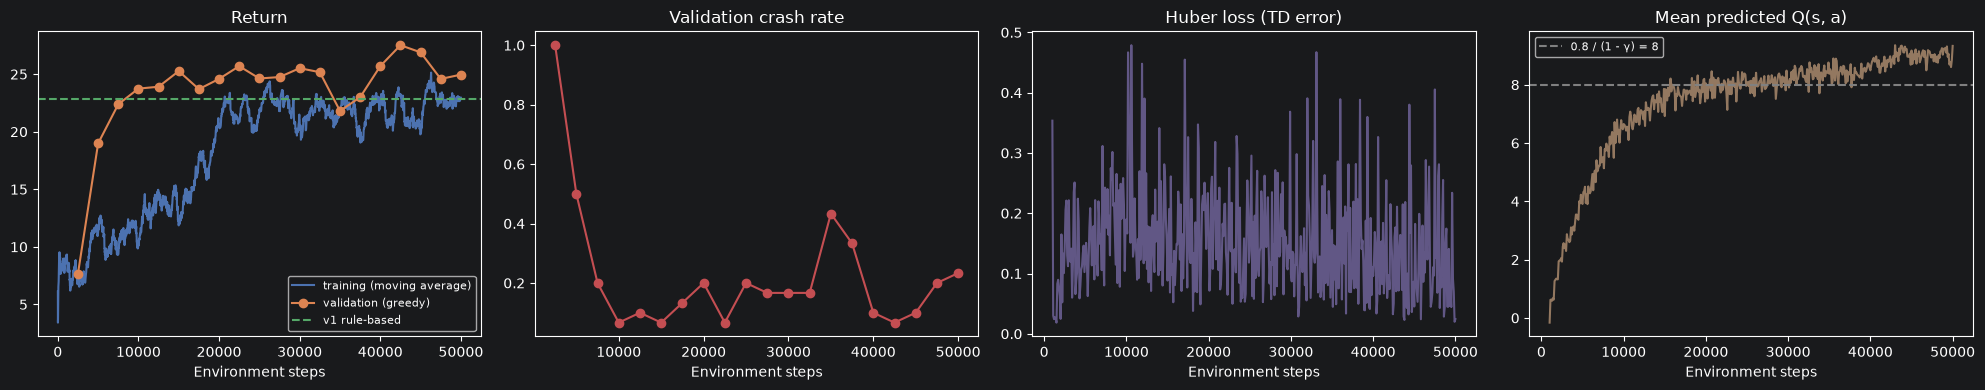

In [7]:
# --- LEARNING CURVES ---

# Moving average over a window.
def moving_average(x, window=50):
    """Average of the last `window` values at every point (shorter at the start)."""

    # As floats.
    x = np.asarray(x, dtype=float)

    # Cumulative sum with a leading zero.
    c = np.concatenate([[0.0], np.cumsum(x)])

    # Start index of each window.
    starts = np.maximum(0, np.arange(1, len(x) + 1) - window)

    # Window sums divided by window lengths.
    return (c[1:] - c[starts]) / (np.arange(1, len(x) + 1) - starts)


# Four panels.
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

# Training return.
axes[0].plot(history["episode_step"], moving_average(history["episode_return"]), color="#4C72B0", label="training (moving average)")

# Validation return.
axes[0].plot(history["val_step"], history["val_return"], marker="o", color="#DD8452", label="validation (greedy)")

# Rule-based reference.
axes[0].axhline(22.83, linestyle="--", color="#55A868", label="v1 rule-based")

# Title.
axes[0].set_title("Return")

# Legend.
axes[0].legend(fontsize=8)

# Validation crash rate.
axes[1].plot(history["val_step"], history["val_crash"], marker="o", color="#C44E52")

# Title.
axes[1].set_title("Validation crash rate")

# Loss.
axes[2].plot(history["loss_step"], history["loss"], color="#8172B3", alpha=0.7)

# Title.
axes[2].set_title("Huber loss (TD error)")

# Mean predicted value.
axes[3].plot(history["loss_step"], history["q"], color="#937860")

# Reference value.
axes[3].axhline(0.8 / (1 - GAMMA), linestyle="--", color="gray", label="0.8 / (1 - γ) = 8")

# Title.
axes[3].set_title("Mean predicted Q(s, a)")

# Legend.
axes[3].legend(fontsize=8)

# Common x label.
for ax in axes:

    # Steps.
    ax.set_xlabel("Environment steps")

# Layout.
plt.tight_layout()

# Render.
plt.show()

## Step 5 — Test: v4 against v3 and the baselines

- The v4 network (best on validation) on the 50 test scenarios.
- The v3 network is loaded from `results/v3_dqn.pt` (same observation) and measured again in the same way, so the two can be compared side by side.
- **Overestimation of both**: predicted $Q(s_0, a_0)$ against the discounted return actually obtained, as in v3.

v4 attention DDQN return 26.83 | crash rate 10.0% | speed 28.50 m/s | distance  816.7 m | length 28.62
v1 rule-based    return 22.83 | crash rate  2.0% | speed 22.55 m/s | distance  670.4 m | length 29.66
v2 Q-learning    return 23.05 | crash rate  8.0% | speed 23.05 m/s | distance  673.7 m | length 29.24
v3 DQN           return 20.55 | crash rate 18.0% | speed 21.90 m/s | distance  578.5 m | length 26.88


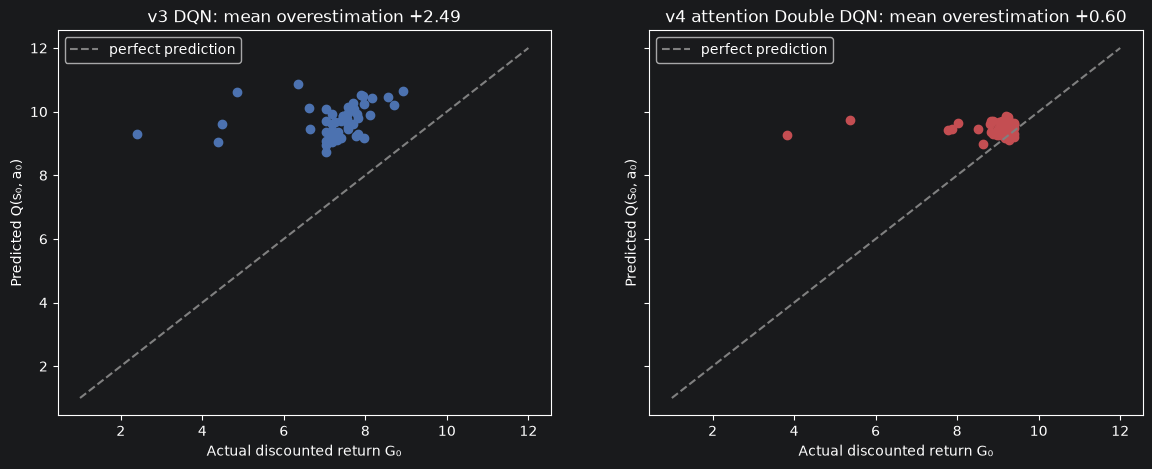

v4 driver, scenario 1000: return 28.74, no crash  (videos/v4_attention_ddqn.gif)


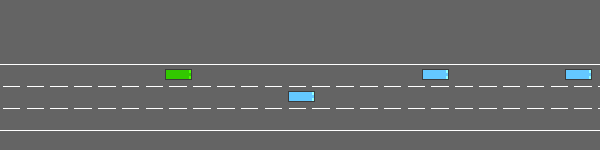

In [8]:
# Multilayer perceptron: observation -> one value per action.
class QNetwork(nn.Module):

    # Declare the layers.
    def __init__(self, obs_dim, n_actions, hidden=256):

        # Initialise the parent class.
        super().__init__()

        # Flatten (10, 5) -> 50, then two hidden layers with ReLU, then one output per action.
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(obs_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_actions),
        )

    # Forward pass.
    def forward(self, obs):
        """obs: (B, 10, 5) float tensor -> Q-values (B, 5)."""

        # Values of all actions.
        return self.net(obs)


# --- TEST EVALUATION ---

# Evaluate v4.
res_v4 = evaluate(dqn_policy, env=env_eval)

# Report.
summary("v4 attention DDQN", res_v4)

# The v3 network, rebuilt and loaded.
v3_net = QNetwork(OBS_DIM, N_ACTIONS).to(device)

# Its trained weights.
v3_net.load_state_dict(torch.load(RESULTS_DIR / "v3_dqn.pt", map_location=device))

# Results of the previous versions.
RESULTS_PATH = RESULTS_DIR / "autopilot_results.json"

# Load them.
results_all = json.loads(RESULTS_PATH.read_text())

# Compare.
for name in ["v1 rule-based", "v2 Q-learning", "v3 DQN"]:

    # Saved means.
    r = results_all[name]

    # Same format as summary().
    print(f"{name:<16} return {r['return']:5.2f} | crash rate {r['crash']:5.1%} | speed {r['speed']:5.2f} m/s | "
          f"distance {r['distance']:6.1f} m | length {r['length']:5.2f}")


# Predicted value at the start of each test episode and discounted return actually obtained.
@torch.no_grad()
def predicted_vs_actual(net):
    """Return two arrays (predicted, actual) over the 50 test scenarios, playing greedily with `net`."""

    # Lists of values.
    predicted, actual = [], []

    # Every test scenario.
    for seed in EVAL_SEEDS:

        # Start.
        obs, _ = env_eval.reset(seed=seed)

        # Value of the best first action.
        predicted.append(net(torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0)).max().item())

        # Discounted return and current discount.
        g, discount = 0.0, 1.0

        # Until the end.
        done = False

        # Play greedily.
        while not done:

            # Step.
            obs, r, terminated, truncated, _ = env_eval.step(greedy_action(net, obs))

            # Add the discounted reward.
            g += discount * r

            # Next discount.
            discount *= GAMMA

            # End?
            done = terminated or truncated

        # Store.
        actual.append(g)

    # As arrays.
    return np.array(predicted), np.array(actual)


# Both networks.
pred_v3, act_v3 = predicted_vs_actual(v3_net)

# v4.
pred_v4, act_v4 = predicted_vs_actual(q_net)

# Two panels.
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

# One panel per network.
for ax, (name, pred, act, colour) in zip(axes, [("v3 DQN", pred_v3, act_v3, "#4C72B0"), ("v4 attention Double DQN", pred_v4, act_v4, "#C44E52")]):

    # Scatter.
    ax.scatter(act, pred, color=colour)

    # Diagonal.
    lims = [1, 12]

    # Draw it.
    ax.plot(lims, lims, linestyle="--", color="gray", label="perfect prediction")

    # Labels.
    ax.set_xlabel("Actual discounted return G₀")

    # y-axis label.
    ax.set_ylabel("Predicted Q(s₀, a₀)")

    # Title with the mean error.
    ax.set_title(f"{name}: mean overestimation {np.mean(pred - act):+.2f}")

    # Legend.
    ax.legend()

# Render.
plt.show()

# The v4 driver on the usual scenario.
show_episode(dqn_policy, seed=1000, filename="v4_attention_ddqn.gif", title="v4 driver, scenario 1000", env=env_render)

## Step 6 — Which cars does the agent look at?

For one test scenario we record, at every decision, the attention weights $\alpha_i$ of the ego query (averaged over the 2 heads). Four moments are drawn as a **top view centred on our car** (the black outline):
- each other car is a rectangle at its relative position, coloured by how much attention it receives (dark = ignored, bright = watched);
- the dashed lines are the lane boundaries;
- positions come from the normalised observation: $x$ is scaled by 200 m and $y$ by 12 m (the normalisation ranges of highway-env for this road).

The ego car also attends to **itself** (its own lane and speed). Its weight is written in the title.

**What to look for:** the car just ahead in our lane should receive most of the attention when it is close; before a lane change, the cars in the target lane, ahead and behind, should light up.

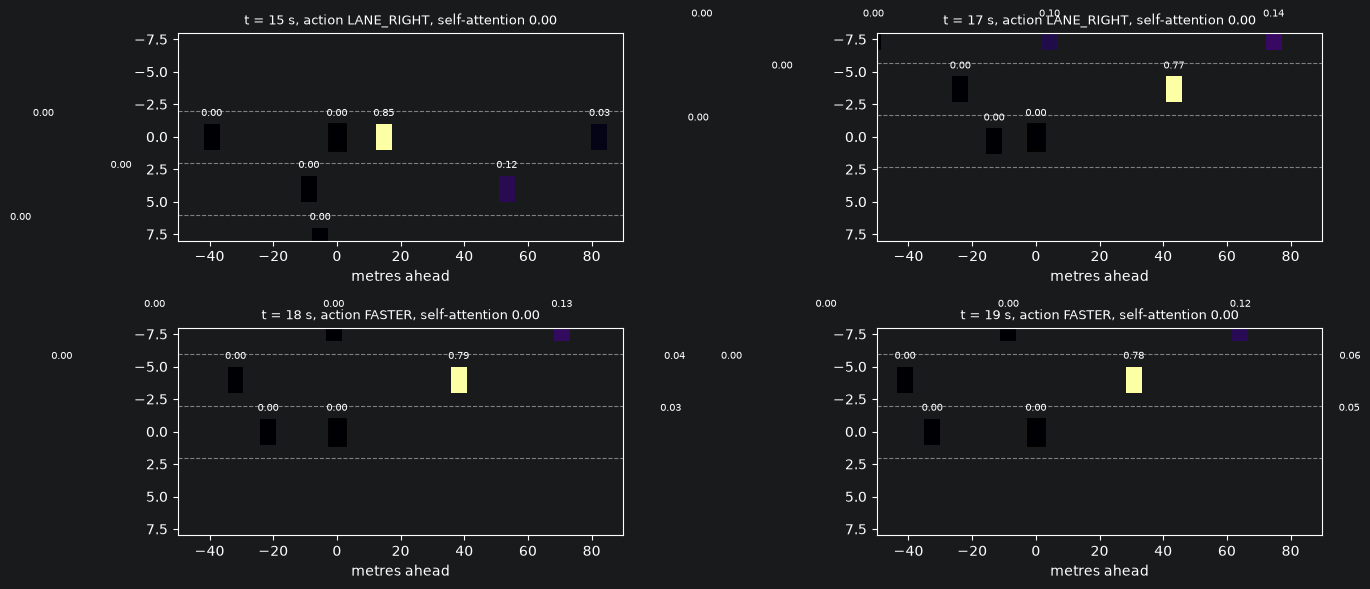

Average attention over the episode: on itself 0.00 | on the most watched other car 0.61
{
  "return": 26.82924120602605,
  "crash": 0.1,
  "speed": 28.502599439560377,
  "distance": 816.6816767745481,
  "length": 28.62
}


In [9]:
# --- ATTENTION PICTURES ---

# Normalisation ranges of the observation: x over +-200 m (5 x max speed 40 m/s), y over +-12 m (3 lanes x 4 m).
X_SCALE, Y_SCALE = 200.0, 12.0

# Lane width in metres.
LANE_WIDTH = 4.0


# Play one test scenario greedily, recording observations, attention and actions.
@torch.no_grad()
def record_attention(seed):
    """Return lists of (observation, attention averaged over heads, action)."""

    # Start.
    obs, _ = env_eval.reset(seed=seed)

    # Records.
    frames = []

    # Until the end.
    done = False

    # Play.
    while not done:

        # Q-values and attention.
        q, att = q_net(torch.as_tensor(obs, dtype=torch.float32).unsqueeze(0), return_attention=True)

        # Greedy action.
        action = int(q.argmax(dim=1).item())

        # Store (attention averaged over the heads).
        frames.append((obs.copy(), att[0].mean(dim=0).numpy(), action))

        # Step.
        obs, _, terminated, truncated, _ = env_eval.step(action)

        # End?
        done = terminated or truncated

    # All decisions.
    return frames


# Draw one decision as a top view coloured by attention.
def draw_attention(ax, obs, weights, action, step):
    """obs: (10, 5) normalised; weights: (10,) attention of the ego query."""

    # Colour map for the attention.
    cmap = plt.cm.inferno

    # Lateral position of our car in metres (absolute), to draw the lane boundaries around it.
    ego_y = obs[0, 2] * Y_SCALE

    # Lane boundaries of a 3-lane road (absolute y = -2, 2, 6, 10), relative to our car.
    for boundary in [-2, 2, 6, 10]:

        # Dashed line.
        ax.axhline(boundary - ego_y, color="gray", linestyle="--", linewidth=0.8)

    # Every vehicle row.
    for i, row in enumerate(obs):

        # Skip empty rows.
        if row[0] < 0.5:

            # Next.
            continue

        # Relative position in metres (the ego is at the origin).
        x, y = (0.0, 0.0) if i == 0 else (row[1] * X_SCALE, row[2] * Y_SCALE)

        # Rectangle of a car (5 m x 2 m), coloured by its attention weight.
        ax.add_patch(Rectangle((x - 2.5, y - 1), 5, 2, facecolor=cmap(weights[i] / weights.max()),
                               edgecolor="black" if i == 0 else "none", linewidth=2))

        # Attention weight written above the car.
        ax.text(x, y - 1.6, f"{weights[i]:.2f}", ha="center", fontsize=7)

    # Window around our car.
    ax.set_xlim(-50, 90)

    # Three lanes around it (y grows downwards, as in the simulator picture).
    ax.set_ylim(8, -8)

    # Equal scale would be too flat: keep the axes as they are, but label them.
    ax.set_xlabel("metres ahead")

    # Title: step, chosen action and attention on itself.
    ax.set_title(f"t = {step} s, action {ACTIONS[action]}, self-attention {weights[0]:.2f}", fontsize=9)


# Record a test scenario.
frames = record_attention(seed=1001)

# Four moments: the decisions with the highest attention on another car.
others = [f[1][1:].max() for f in frames]

# Indices of the 4 most "focused" decisions, in time order.
moments = sorted(np.argsort(others)[-4:])

# 2 x 2 grid.
fig, axes = plt.subplots(2, 2, figsize=(14, 6))

# One panel per moment.
for ax, t in zip(axes.flat, moments):

    # Draw it.
    draw_attention(ax, frames[t][0], frames[t][1], frames[t][2], t)

# Layout.
plt.tight_layout()

# Render.
plt.show()

# How the attention is spread on average: on itself, on the car with most attention, and on all the others.
self_att = np.mean([f[1][0] for f in frames])

# Strongest other car.
top_att = np.mean([f[1][1:].max() for f in frames])

# Report.
print(f"Average attention over the episode: on itself {self_att:.2f} | on the most watched other car {top_att:.2f}")

# --- SAVE THE RESULTS ---

# Means of the v4 driver.
results_all["v4 attention DDQN"] = {metric: float(values.mean()) for metric, values in res_v4.items()}

# Write the file.
RESULTS_PATH.write_text(json.dumps(results_all, indent=2))

# Show the v4 entry.
print(json.dumps(results_all["v4 attention DDQN"], indent=2))

## Results and conclusions

### Test results (the same 50 scenarios as v1–v3)
| Driver | Return | Crash rate | Mean speed | Distance |
|---|---|---|---|---|
| v1 rule-based | 22.83 | **2%** | 22.5 m/s | 670 m |
| v2 Q-learning (hand-made features) | 23.05 | 8% | 23.0 m/s | 674 m |
| v3 DQN (MLP) | 20.55 | 18% | 21.9 m/s | 579 m |
| **v4 attention + Double + Dueling DQN** | **26.83** | 10% | **28.5 m/s** | **817 m** |

### 1. The biggest jump of the project
- v4 scores **+3.8** over the best previous driver and **+6.3** over v3.
- It does this with **29,702 parameters**, 37% of the 80,133 of the v3 MLP: what changed is the structure of the network, not its size.
- It earns **0.94 per decision** (26.83 / 28.62), against 0.77 for the rule-based driver (22.83 / 29.66).
- It drives at 28.5 m/s, near the top of the rewarded speed range [20, 30], and covers 22% more road than the rule-based driver.

### 2. Better is not the same as safer: the agent optimises the reward we wrote
- v4 crashes in **10%** of the scenarios (5 of 50); the rule-based driver crashes in 2%.
- This trade-off is a direct consequence of the reward:
  - driving fast pays in **every second of every episode**;
  - a crash only costs the seconds that remain.
- Taking a little more risk to go faster is therefore the *right* answer to the question we asked.
- To get a more careful driver we would change the **reward** (for example a larger `collision_reward`), not the algorithm.
- Reward design comes back in v5.

### 3. The overestimation is almost gone
- The mean overestimation went from **+2.49** (v3) to **+0.60** (v4): Double DQN works as the theory says.
- The v4 points sit close to the diagonal, around 9–9.5.
- The two points far on the left (actual return 3.8 and 5.4) are episodes that end in a crash. At the start of the episode nothing announces a crash 10–20 seconds later, so no value function could predict it. This is unpredictability, not bias.
- The mean predicted Q during training settles around 9, which matches the reward rate: $0.94 / (1 - 0.9) \approx 9.4$.

### 4. Learning curves
- The validation return passes the rule-based driver **already at 10,000 steps** (23.75); v3 never got there.
- Training is still not perfectly stable. At 35,000 steps the validation crash rate jumps to 43%, then recovers.
- The best model is at 42,500 steps (validation 27.52). Its test return (26.83) is close to that, so the 30 validation episodes gave a reliable selection.
- The training return (ε = 0.05) stays below the greedy validation: in dense traffic, a random action 5% of the time is enough to cause crashes.
- The Huber loss does not go down. This is normal in RL: the targets move as the network improves.

### 5. What the attention looks at
- On average **0.61** of the attention goes to **a single car**, and the cars behind get almost nothing.
- **t = 15 s:** the car 15 m ahead in our lane takes 0.85 of the attention, and the agent chooses LANE_RIGHT to overtake it.
- **t = 17–19 s:** in the new lane, the attention moves to the car 40 → 30 m ahead in the adjacent lane (about 0.78) while the agent accelerates (FASTER). It watches the car it is about to pass, which is the one that could cut into its lane.
- **The self-attention is 0.00**, contrary to what we predicted in Step 6.
  - The reason is the residual connection $z = W_o(\cdot) + e_0$: the ego's own features are already added back after the attention.
  - So the query only needs to fetch information about the *other* cars.
  - A prediction proven wrong by the data is a result too.

### 6. Limits and next step
- The agent still presses one of **5 buttons** once per second, and a hand-written low-level controller does the actual steering.
- In **v5** we take the steering wheel: a racetrack where the action is a **continuous** steering angle.
- DQN needs $\max_a Q(s, a)$ over a finite list of actions. With a continuous wheel there are infinitely many actions, so we learn the policy directly: **policy gradient** (REINFORCE, then PPO).